In [ ]:
import numpy as np
import random

def generate_maze(rows=31, cols=31):
    maze = np.ones((rows, cols), dtype=int)

    # Start at the top-left open cell
    start = (1, 1)
    maze[start] = 0

    stack = [start]
    directions = [(-2, 0), (2, 0), (0, -2), (0, 2)]

    while stack:
        r, c = stack[-1]

        # Find unvisited cells two steps away
        random.shuffle(directions)
        next_cells = []

        for dr, dc in directions:
            nr, nc = r + dr, c + dc

            if 1 <= nr < rows - 1 and 1 <= nc < cols - 1:
                if maze[nr, nc] == 1:
                    next_cells.append((nr, nc, dr, dc))

        if next_cells:
            nr, nc, dr, dc = next_cells[0]

            # Carve the wall between the cells
            maze[r + dr // 2, c + dc // 2] = 0
            maze[nr, nc] = 0

            stack.append((nr, nc))
        else:
            stack.pop()

    return maze


# Create a large maze
maze = generate_maze(31, 31)

H, W = maze.shape
START, GOAL = (1, 1), (H - 2, W - 2)

print("Maze size:", maze.shape)
print("Start:", START)
print("Goal:", GOAL)

Maze size: (31, 31)
Start: (1, 1)
Goal: (29, 29)


In [ ]:
import numpy as np
from collections import deque
# 1 = wall, 0 = open. Any carved maze works; see make_fig3.py in this project
# for the randomized-DFS carver that guarantees the goal is reachable.
H, W = maze.shape
START, GOAL = (1, 1), (H-2, W-2)


def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1,0), (1,0), (0,-1), (0,1)):  # up, down, left, right
        nr, nc = r+dr, c+dc
        if 0 <= nr < H and 0 <= nc < W:  # BOUNDS FIRST
            if maze[nr, nc] == 0:  # then contents
                yield (nr, nc)

In [ ]:
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}  # doubles as the explored set
    order = {}  # cell -> the step at which it was expanded

    while frontier:
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()
        # <---- THE ONLY DIFFERENCE BETWEEN THE TWO ALGORITHMS
        if node in order: continue
        order[node] = len(order)
        if node == goal: break

        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)

    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1]


for mode in ('bfs', 'dfs'):
    order, path = search(START, GOAL, mode)
    print(f'{mode.upper()}: {len(order)} expanded, path length {len(path)}')

BFS: 259 expanded, path length 149
DFS: 169 expanded, path length 149


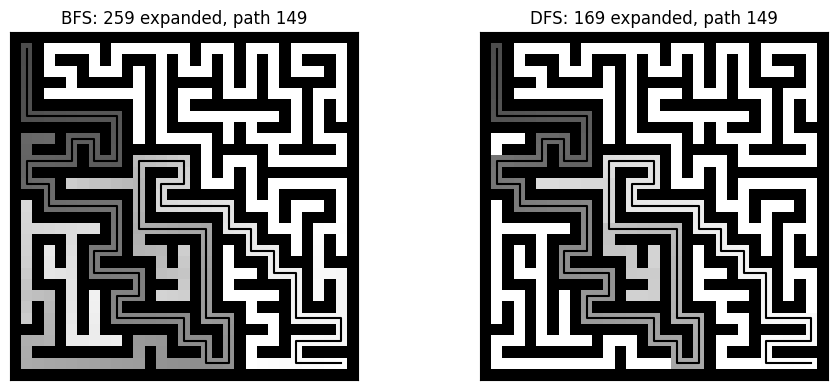

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mode in zip(axes, ['bfs', 'dfs']):
    order, path = search(START, GOAL, mode)
    grid = np.full(maze.shape, np.nan)  # nan = never expanded
    for (r, c), k in order.items():
        grid[r, c] = k  # shade by expansion order
    ax.imshow(maze, cmap='binary')
    ax.imshow(grid, cmap='Greys_r', alpha=0.7)
    ax.plot([c for r, c in path], [r for r, c in path], lw=1.5, color='k')
    ax.set_title(f'{mode.upper()}: {len(order)} expanded, path {len(path)}')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Image saved as: maze_search_2026-09-15_03-17-16.png


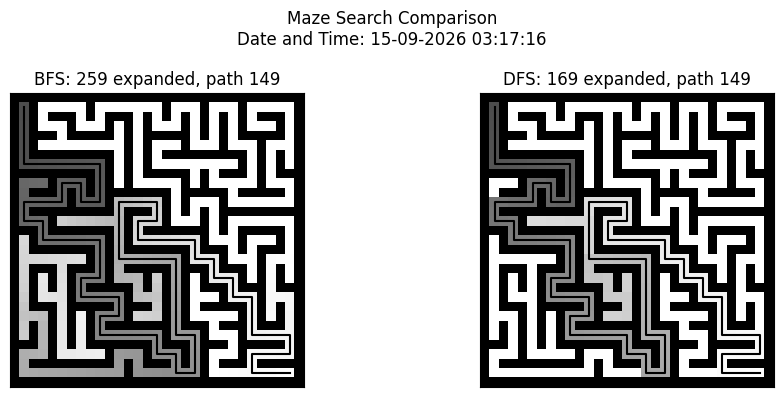

In [ ]:
import matplotlib.pyplot as plt
from datetime import datetime

# Get current date and time
now = datetime.now()
timestamp = now.strftime("%Y-%m-%d_%H-%M-%S")
display_time = now.strftime("%d-%m-%Y %H:%M:%S")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, mode in zip(axes, ['bfs', 'dfs']):
    order, path = search(START, GOAL, mode)
    grid = np.full(maze.shape, np.nan)

    for (r, c), k in order.items():
        grid[r, c] = k

    ax.imshow(maze, cmap='binary')
    ax.imshow(grid, cmap='Greys_r', alpha=0.7)
    ax.plot(
        [c for r, c in path],
        [r for r, c in path],
        lw=1.5,
        color='k'
    )
    ax.set_title(
        f'{mode.upper()}: {len(order)} expanded, path {len(path)}'
    )
    ax.set_xticks([])
    ax.set_yticks([])

# Add date and time to the image
fig.suptitle(
    f'Maze Search Comparison\nDate and Time: {display_time}',
    fontsize=12
)

plt.tight_layout()

# Save the image with date and time in the filename
filename = f'maze_search_{timestamp}.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')

print(f'Image saved as: {filename}')

plt.show()